# PhonePe Data Analytics Case Study

**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn  
**Analysis level:** State, district, transaction category, device brand and app engagement

## Project objective
Explore the supplied PhonePe transaction, user, device and district-demographic datasets to identify geographic patterns, transaction mix, app engagement trends and potential relationships between population density and transaction activity.

> This notebook uses only the CSV files included in this repository. It does not claim to establish causation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
OUTPUT_DIR = Path("visualizations")
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Load the five datasets

In [2]:
state_txn_users = pd.read_csv(DATA_DIR / "State_Txn_and_Users.csv")
state_txn_split = pd.read_csv(DATA_DIR / "State_TxnSplit.csv")
state_device = pd.read_csv(DATA_DIR / "State_DeviceData.csv")
district_txn_users = pd.read_csv(DATA_DIR / "District_Txn_and_Users.csv")
district_demo = pd.read_csv(DATA_DIR / "District_Demographics.csv")

datasets = {
    "State transactions and users": state_txn_users,
    "State transaction split": state_txn_split,
    "State device data": state_device,
    "District transactions and users": district_txn_users,
    "District demographics": district_demo,
}
for name, frame in datasets.items():
    print(f"{name}: {frame.shape[0]:,} rows × {frame.shape[1]} columns")

State transactions and users: 10,248 rows × 8 columns
State transaction split: 10,248 rows × 7 columns
State device data: 10,248 rows × 7 columns
District transactions and users: 10,248 rows × 10 columns
District demographics: 742 rows × 8 columns


## 3. Initial inspection and data quality

In [3]:
for name, frame in datasets.items():
    print(f"\\n--- {name} ---")
    display(frame.head(3))
    print("Missing values:")
    display(frame.isna().sum().to_frame("missing_count"))

\n--- State transactions and users ---


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,"2,018.00",1.00,"6,658","1,46,31,761","2,198","6,740",0
1,Andaman & Nicobar Islands,"2,018.00",2.00,"11,340","2,83,38,536","2,499","9,405",0
2,Andaman & Nicobar Islands,"2,018.00",3.00,"16,265","5,55,57,471","3,416","12,149",0


Missing values:


,missing_count
State,9744
Year,9744
Quarter,9744
Transactions,9744
Amount (INR),9745
ATV (INR),9744
Registered Users,9744
App Opens,9744


\n--- State transaction split ---


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,"2,018.00",1.00,Recharge & bill payments,"4,200","18,45,307",439
1,Andaman & Nicobar Islands,"2,018.00",1.00,Peer-to-peer payments,"1,871","1,21,38,655","6,488"
2,Andaman & Nicobar Islands,"2,018.00",1.00,Merchant payments,298,"4,52,507","1,518"


... (10 outputs left out)

\n--- District demographics ---


,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,"40,83,315","19,130",213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,"41,70,468","15,152",275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,"51,51,549","10,807",477,AP03,East Godavari


Missing values:


,missing_count
State,0
District,0
Headquarters,0
Population,14
Area (sq km),15
Density,18
Code,0
Alternate Name,0


## 4. Clean numeric fields

In [4]:
def clean_numeric(series):
    # Remove currency symbols, thousands separators and other non-numeric characters.
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.\\-]", "", regex=True),
        errors="coerce"
    )

for frame in [state_txn_users, state_txn_split, district_txn_users]:
    for column in ["Transactions", "Amount (INR)", "ATV (INR)", "Registered Users", "App Opens"]:
        if column in frame.columns:
            frame[column] = clean_numeric(frame[column])

for column in ["Registered Users", "Percentage"]:
    if column in state_device.columns:
        state_device[column] = clean_numeric(state_device[column])

for column in ["Population", "Area (sq km)", "Density"]:
    if column in district_demo.columns:
        district_demo[column] = clean_numeric(district_demo[column])

for frame in [state_txn_users, state_txn_split, state_device, district_txn_users]:
    for column in ["Year", "Quarter"]:
        if column in frame.columns:
            frame[column] = pd.to_numeric(frame[column], errors="coerce")

# Drop fully empty columns such as the blank unnamed field in the supplied device file.
state_device = state_device.dropna(axis=1, how="all")

# Remove exact duplicate records; retain missing numeric values as NaN until aggregation.
for frame in [state_txn_users, state_txn_split, state_device, district_txn_users, district_demo]:
    frame.drop_duplicates(inplace=True)

print("Cleaning complete.")

Cleaning complete.


/tmp/ipykernel_768/3046668595.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frame.drop_duplicates(inplace=True)


## 5. Geographic coverage

In [5]:
print("States in state-level transaction data:", state_txn_users["State"].nunique())
print("Districts in demographics data:", district_demo["District"].nunique())
print("States represented in district demographics:", district_demo["State"].nunique())

districts_per_state = district_demo.groupby("State")["District"].nunique().sort_values(ascending=False)
display(districts_per_state.head(10))

States in state-level transaction data: 36
Districts in demographics data: 736
States represented in district demographics: 36


State
Uttar Pradesh     75
Madhya Pradesh    55
Bihar             38
Tamil Nadu        38
Maharashtra       36
Assam             34
Gujarat           33
Telangana         33
Rajasthan         33
Karnataka         31
Name: District, dtype: int64

## 6. State-wise transaction performance

Top 5 states by total transactions


,Transactions
State,
Karnataka,"2,981,044,533.00"
Maharashtra,"2,833,670,154.00"
Telangana,"2,347,430,243.00"
Andhra Pradesh,"1,781,091,169.00"
Rajasthan,"1,382,918,930.00"


Bottom 5 states by total transactions


,Transactions
State,
Lakshadweep,"71,610.00"
Andaman & Nicobar Islands,"1,223,565.00"
Ladakh,"1,880,109.00"
Mizoram,"2,162,776.00"
Meghalaya,"5,648,913.00"


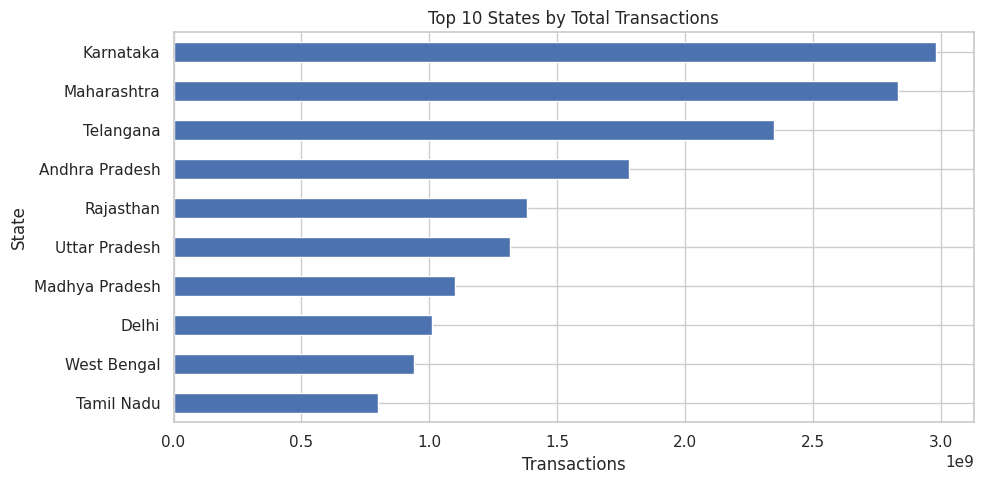

In [6]:
state_totals = state_txn_users.groupby("State", dropna=True)["Transactions"].sum().sort_values(ascending=False)
print("Top 5 states by total transactions")
display(state_totals.head(5).to_frame("Transactions"))
print("Bottom 5 states by total transactions")
display(state_totals.tail(5).sort_values().to_frame("Transactions"))

ax = state_totals.head(10).sort_values().plot(kind="barh", figsize=(10, 5), title="Top 10 States by Total Transactions")
ax.set_xlabel("Transactions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_states_by_transactions.png", dpi=160)
plt.show()

## 7. Quarterly app engagement trend

,Year,Quarter,App Opens,Period
4,"2,019.00",1.00,0.00,2019-Q1
5,"2,019.00",2.00,"920,409,531.00",2019-Q2
6,"2,019.00",3.00,"3,448,355,858.00",2019-Q3
7,"2,019.00",4.00,"4,301,061,532.00",2019-Q4
8,"2,020.00",1.00,"4,768,934,587.00",2020-Q1
9,"2,020.00",2.00,"4,357,622,260.00",2020-Q2
10,"2,020.00",3.00,"5,739,306,412.00",2020-Q3
11,"2,020.00",4.00,"7,461,591,732.00",2020-Q4
12,"2,021.00",1.00,"8,635,472,151.00",2021-Q1
13,"2,021.00",2.00,"9,630,577,372.00",2021-Q2


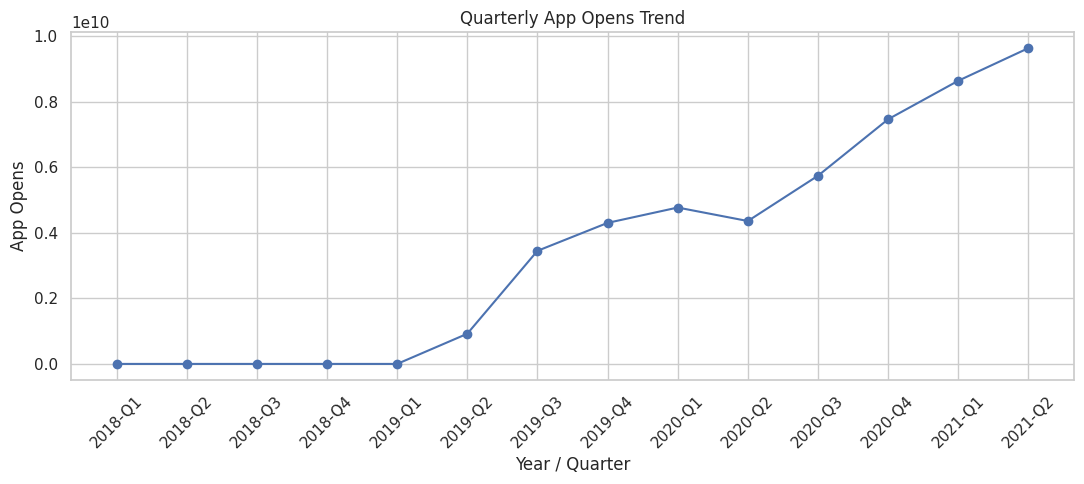

In [7]:
app_trend = (
    state_txn_users.groupby(["Year", "Quarter"], dropna=True)["App Opens"]
    .sum().reset_index().sort_values(["Year", "Quarter"])
)
app_trend["Period"] = app_trend["Year"].astype(int).astype(str) + "-Q" + app_trend["Quarter"].astype(int).astype(str)
display(app_trend.tail(10))

plt.figure(figsize=(11, 5))
plt.plot(app_trend["Period"], app_trend["App Opens"], marker="o")
plt.title("Quarterly App Opens Trend")
plt.xlabel("Year / Quarter")
plt.ylabel("App Opens")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "app_opens_trend.png", dpi=160)
plt.show()

## 8. Transaction category mix

Transaction category totals for 2021 Q2


,Transactions
Transaction Type,
Peer-to-peer payments,"1,744,265,068.00"
Merchant payments,"1,499,624,295.00"
Recharge & bill payments,"685,022,045.00"
Others,"9,061,701.00"
Financial Services,"3,397,356.00"


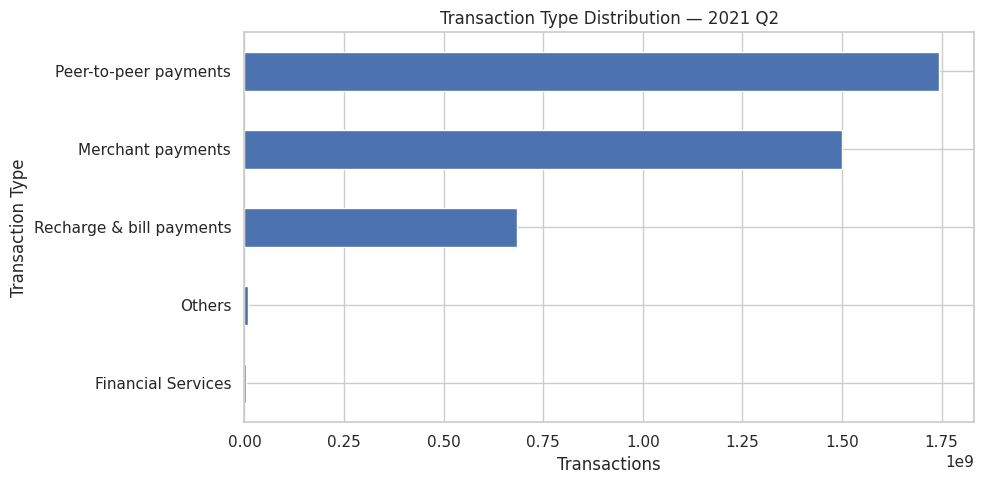

In [8]:
valid_periods = state_txn_split.dropna(subset=["Year", "Quarter"])
latest_year = valid_periods["Year"].max()
latest_quarter = valid_periods.loc[valid_periods["Year"] == latest_year, "Quarter"].max()
latest_split = valid_periods[
    (valid_periods["Year"] == latest_year) &
    (valid_periods["Quarter"] == latest_quarter)
]
transaction_mix = latest_split.groupby("Transaction Type")["Transactions"].sum().sort_values(ascending=False)
print(f"Transaction category totals for {int(latest_year)} Q{int(latest_quarter)}")
display(transaction_mix.to_frame("Transactions"))

ax = transaction_mix.sort_values().plot(kind="barh", figsize=(10, 5), title=f"Transaction Type Distribution — {int(latest_year)} Q{int(latest_quarter)}")
ax.set_xlabel("Transactions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "transaction_type_distribution.png", dpi=160)
plt.show()

## 9. Device brand analysis

,Registered Users
Brand,
Xiaomi,"615,566,524.00"
Samsung,"480,799,591.00"
Vivo,"411,369,522.00"
Oppo,"283,522,909.00"
Others,"211,221,642.00"
Realme,"134,416,015.00"
Apple,"67,132,534.00"
Motorola,"57,086,814.00"
OnePlus,"44,184,950.00"


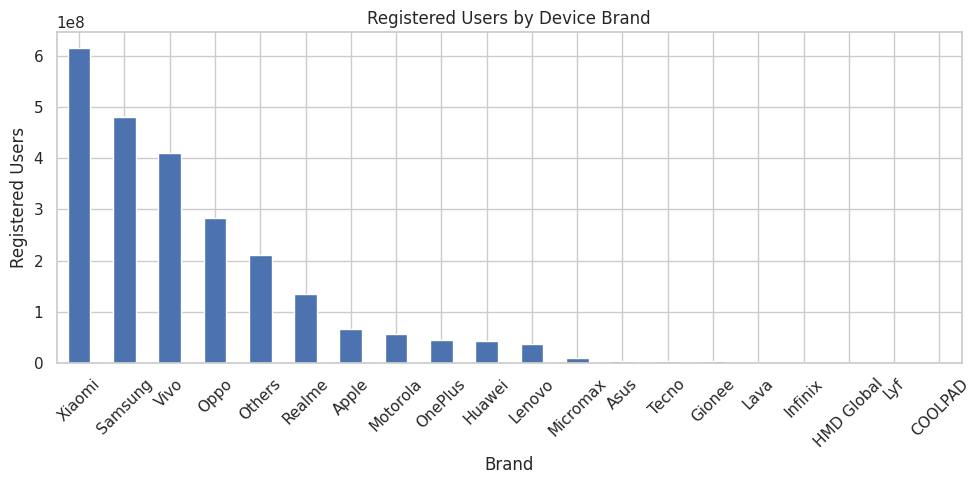

In [9]:
brand_users = state_device.groupby("Brand")["Registered Users"].sum().sort_values(ascending=False)
display(brand_users.to_frame("Registered Users"))

ax = brand_users.plot(kind="bar", figsize=(10, 5), title="Registered Users by Device Brand")
ax.set_ylabel("Registered Users")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "device_brand_users.png", dpi=160)
plt.show()

## 10. District demographics

,State,District,Population
691,West Bengal,North 24 Parganas,"10,082,852.00"
235,Karnataka,Bangalore Urban,"9,588,910.00"
356,Maharashtra,Pune,"9,426,959.00"
348,Maharashtra,Mumbai suburban,"9,332,481.00"
695,West Bengal,South 24 Parganas,"8,161,961.00"
363,Maharashtra,Thane,"8,070,032.00"
140,Gujarat,Ahmedabad,"7,208,200.00"
509,Tamil Nadu,Chennai,"7,139,882.00"
689,West Bengal,Murshidabad,"7,102,430.00"
489,Rajasthan,Jaipur,"6,663,971.00"


,State,District,Density
731,Delhi,North East Delhi,"36,155.00"
727,Delhi,Central Delhi,"27,730.00"
728,Delhi,East Delhi,"27,132.00"
687,West Bengal,Kolkata,"24,252.00"
348,Maharashtra,Mumbai suburban,"21,000.00"
347,Maharashtra,Mumbai City,"20,036.00"
737,Delhi,West Delhi,"19,563.00"
548,Telangana,Hyderabad,"18,172.00"
509,Tamil Nadu,Chennai,"17,000.00"
730,Delhi,North Delhi,"14,557.00"


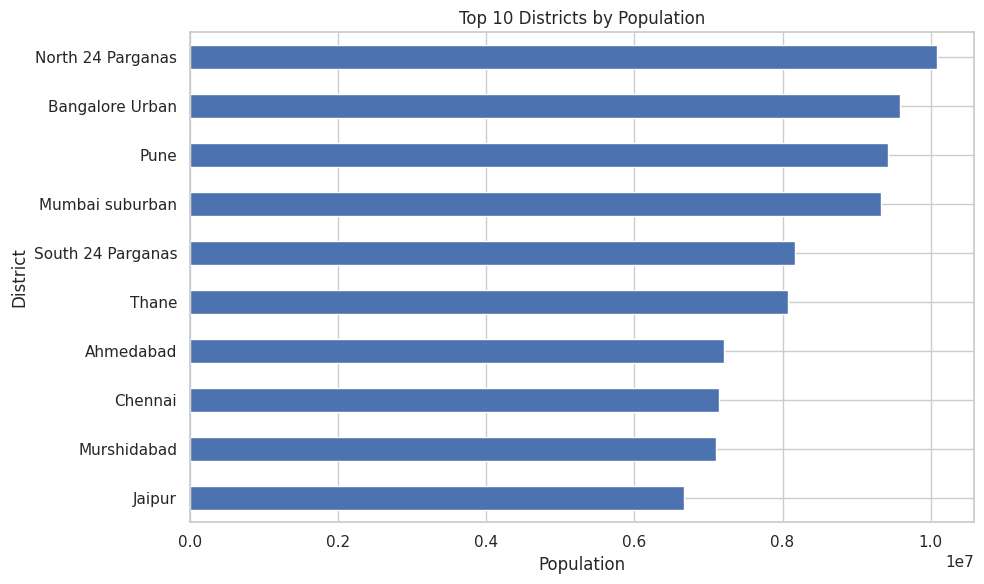

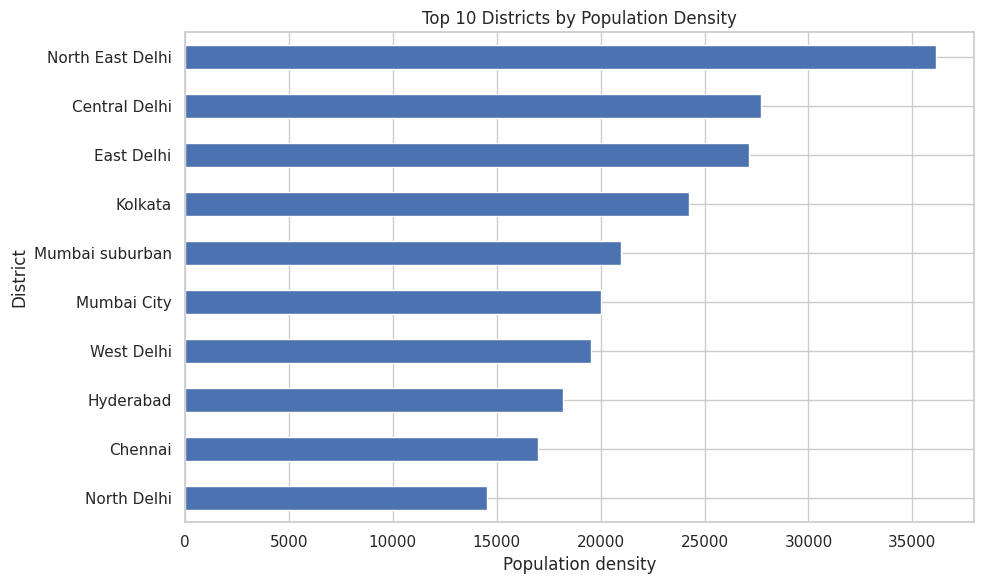

In [10]:
top_population = district_demo.nlargest(10, "Population")
top_density = district_demo.nlargest(10, "Density")

display(top_population[["State", "District", "Population"]])
display(top_density[["State", "District", "Density"]])

ax = top_population.sort_values("Population").plot(
    kind="barh", x="District", y="Population", legend=False,
    figsize=(10, 6), title="Top 10 Districts by Population"
)
ax.set_xlabel("Population")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_districts_population.png", dpi=160)
plt.show()

ax = top_density.sort_values("Density").plot(
    kind="barh", x="District", y="Density", legend=False,
    figsize=(10, 6), title="Top 10 Districts by Population Density"
)
ax.set_xlabel("Population density")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_districts_density.png", dpi=160)
plt.show()

## 11. Registered-user-to-population ratio

,Average user-to-population ratio
State,
Delhi,4.87
Chandigarh,0.26
Dadra & Nagar Haveli and Daman & Diu,0.25
Goa,0.23
Andhra Pradesh,0.22
Telangana,0.19
Haryana,0.19
Karnataka,0.16
Maharashtra,0.15


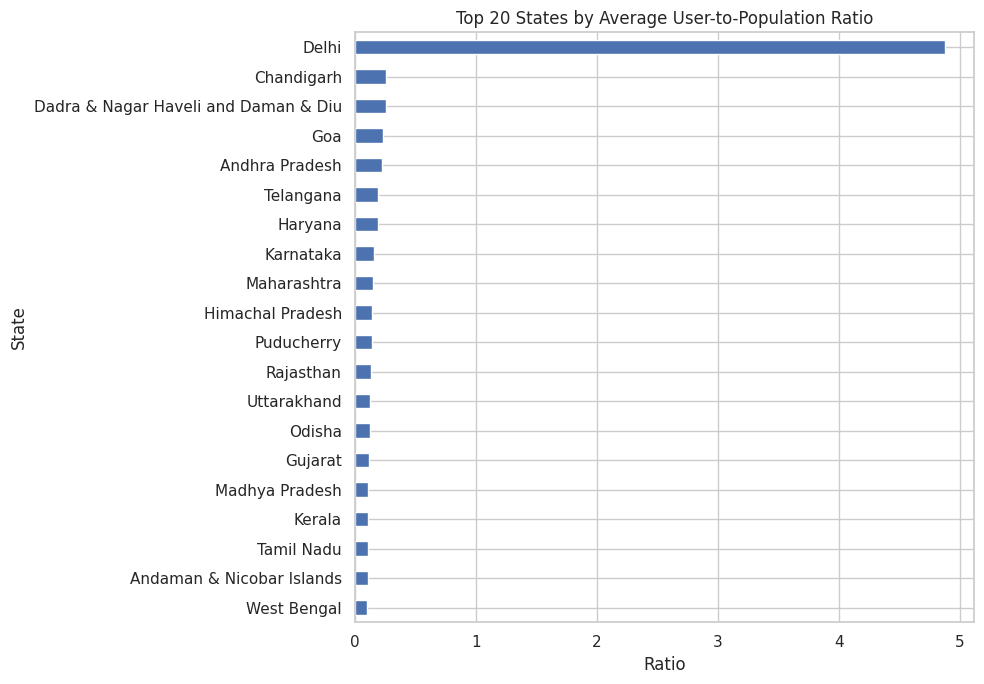

In [11]:
district_merged = district_txn_users.merge(
    district_demo, on=["State", "District", "Code"], how="inner",
    suffixes=("_txn", "_demo")
)
district_merged["User_Pop_Ratio"] = (
    district_merged["Registered Users"] /
    district_merged["Population"].replace(0, np.nan)
)
state_user_population_ratio = district_merged.groupby("State")["User_Pop_Ratio"].mean().dropna().sort_values(ascending=False)
display(state_user_population_ratio.head(10).to_frame("Average user-to-population ratio"))

ax = state_user_population_ratio.head(20).sort_values().plot(
    kind="barh", figsize=(10, 7), title="Top 20 States by Average User-to-Population Ratio"
)
ax.set_xlabel("Ratio")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "user_population_ratio.png", dpi=160)
plt.show()

## 12. Population density and transaction activity

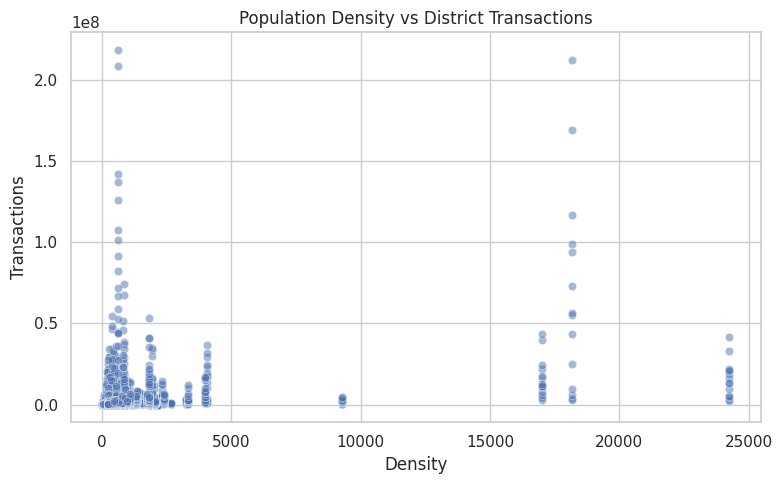

Pearson correlation: 0.308
Correlation indicates association only; it does not establish causation.


In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=district_merged, x="Density", y="Transactions", alpha=0.5)
plt.title("Population Density vs District Transactions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "density_vs_transactions.png", dpi=160)
plt.show()

density_transaction_correlation = district_merged[["Density", "Transactions"]].corr().iloc[0, 1]
print("Pearson correlation:", round(density_transaction_correlation, 3))
print("Correlation indicates association only; it does not establish causation.")

## 13. Transactions per registered user

In [13]:
state_txn_users["Transactions_per_User"] = (
    state_txn_users["Transactions"] /
    state_txn_users["Registered Users"].replace(0, np.nan)
)
transactions_per_user = state_txn_users.groupby("State")["Transactions_per_User"].mean().dropna().sort_values(ascending=False)
print("Top 5 states")
display(transactions_per_user.head(5).to_frame("Average transactions per user"))
print("Bottom 5 states")
display(transactions_per_user.tail(5).sort_values().to_frame("Average transactions per user"))

Top 5 states


,Average transactions per user
State,
Telangana,12.46
Karnataka,11.84
Delhi,9.23
Andhra Pradesh,9.11
Odisha,8.26


Bottom 5 states


,Average transactions per user
State,
Lakshadweep,2.00
Andaman & Nicobar Islands,2.24
Ladakh,2.59
Tripura,3.13
Mizoram,3.22


## 14. State-level transaction reconciliation

In [14]:
district_quarterly = district_txn_users.groupby(
    ["State", "Year", "Quarter"], dropna=True
)["Transactions"].sum().reset_index(name="District_Transactions")

state_quarterly = state_txn_users.groupby(
    ["State", "Year", "Quarter"], dropna=True
)["Transactions"].sum().reset_index(name="State_Transactions")

reconciliation = state_quarterly.merge(
    district_quarterly, on=["State", "Year", "Quarter"], how="inner"
)
reconciliation["Difference"] = (
    reconciliation["State_Transactions"] - reconciliation["District_Transactions"]
)
print("Matched state-quarter records:", len(reconciliation))
print("Records with non-zero difference:", int((reconciliation["Difference"].abs() > 1e-6).sum()))
display(reconciliation.loc[reconciliation["Difference"].abs() > 1e-6].head(20))

Matched state-quarter records: 504
Records with non-zero difference: 0


,State,Year,Quarter,State_Transactions,District_Transactions,Difference


## 15. Key findings and limitations

In [15]:
print("Top 5 states by transaction volume:")
display(state_totals.head(5))
print("Top transaction categories in the latest available quarter:")
display(transaction_mix.head(5))
print("Top device brands by registered users:")
display(brand_users.head(5))
print("Highest-population districts:")
display(top_population[["State", "District", "Population"]].head(5))
print("Density / transaction correlation:", round(density_transaction_correlation, 3))

Top 5 states by transaction volume:


State
Karnataka        2,981,044,533.00
Maharashtra      2,833,670,154.00
Telangana        2,347,430,243.00
Andhra Pradesh   1,781,091,169.00
Rajasthan        1,382,918,930.00
Name: Transactions, dtype: float64

Top transaction categories in the latest available quarter:


Transaction Type
Peer-to-peer payments      1,744,265,068.00
Merchant payments          1,499,624,295.00
Recharge & bill payments     685,022,045.00
Others                         9,061,701.00
Financial Services             3,397,356.00
Name: Transactions, dtype: float64

Top device brands by registered users:


Brand
Xiaomi    615,566,524.00
Samsung   480,799,591.00
Vivo      411,369,522.00
Oppo      283,522,909.00
Others    211,221,642.00
Name: Registered Users, dtype: float64

Highest-population districts:


,State,District,Population
691,West Bengal,North 24 Parganas,"10,082,852.00"
235,Karnataka,Bangalore Urban,"9,588,910.00"
356,Maharashtra,Pune,"9,426,959.00"
348,Maharashtra,Mumbai suburban,"9,332,481.00"
695,West Bengal,South 24 Parganas,"8,161,961.00"


Density / transaction correlation: 0.308


### Interpretation notes
- Transaction totals and user counts are aggregated from the supplied files; they should be interpreted in the context of the dataset's reporting period and definitions.
- A high transaction count does not necessarily mean higher profitability or customer satisfaction.
- Registered-user-to-population ratios are descriptive approximations, not verified market penetration rates.
- Population density and transaction activity may be influenced by factors not represented in these files.
- The supplied device dataset includes a fully blank unnamed column; it is dropped during cleaning.